## Load Dataset

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('car_data.csv')

## Data cleaning

In [2]:
print("Shape:", df.shape)
print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates()

print("\nMissing values:\n", df.isnull().sum())
df = df.dropna()

# Standardize categorical text: strip whitespace, lowercase, then title-case for consistency
for col in ['Fuel_Type', 'Seller_Type', 'Transmission']:
    df[col] = df[col].str.strip().str.lower().str.title()

print("\nUnique Fuel_Type values:", df['Fuel_Type'].unique())

Shape: (301, 9)
Duplicates: 2

Missing values:
 Car_Name         0
Year             0
Selling_Price    0
Present_Price    0
Kms_Driven       0
Fuel_Type        0
Seller_Type      0
Transmission     0
Owner            0
dtype: int64

Unique Fuel_Type values: <StringArray>
['Petrol', 'Diesel', 'Cng']
Length: 3, dtype: str


## Feature engineering

In [3]:
current_year = 2024
df['Car_Age'] = current_year - df['Year']

df['Brand'] = df['Car_Name'].str.split().str[0]

print(df[['Car_Name', 'Brand', 'Year', 'Car_Age']].head())
print("\nUnique brands:", df['Brand'].nunique())

  Car_Name  Brand  Year  Car_Age
0     ritz   ritz  2014       10
1      sx4    sx4  2013       11
2     ciaz   ciaz  2017        7
3  wagon r  wagon  2011       13
4    swift  swift  2014       10

Unique brands: 44


## EDA

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

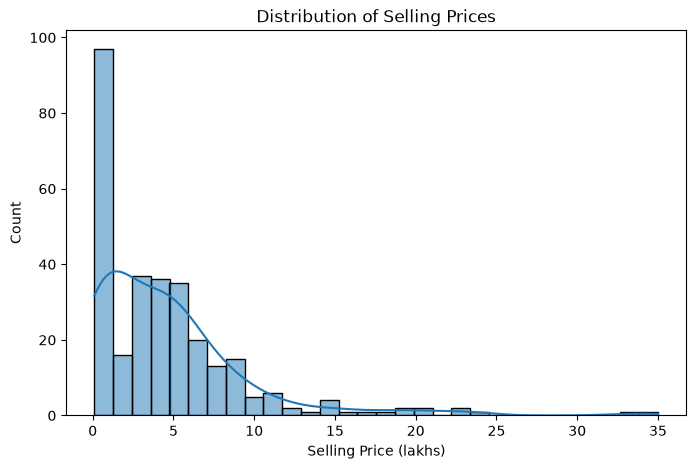

In [5]:
# Distribution of selling prices
plt.figure(figsize=(8, 5))
sns.histplot(df['Selling_Price'], bins=30, kde=True)
plt.title('Distribution of Selling Prices')
plt.xlabel('Selling Price (lakhs)')
plt.show()

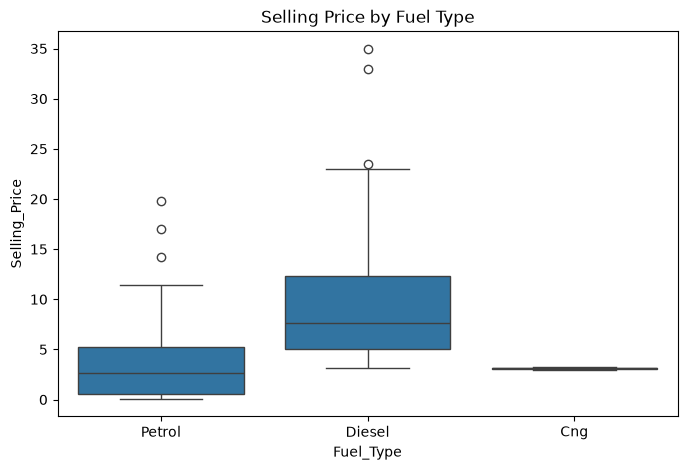

In [6]:
# Price vs fuel type
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Fuel_Type', y='Selling_Price')
plt.title('Selling Price by Fuel Type')
plt.show()

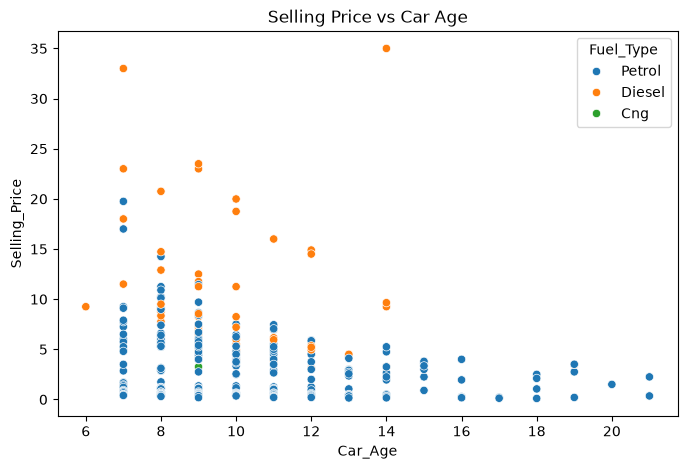

In [7]:
# Price vs car age
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Car_Age', y='Selling_Price', hue='Fuel_Type')
plt.title('Selling Price vs Car Age')
plt.show()

## Encode categorical variables

In [8]:
df_encoded = pd.get_dummies(df, columns=['Fuel_Type', 'Seller_Type', 'Transmission'], drop_first=True)

print(df_encoded.columns.tolist())

['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Kms_Driven', 'Owner', 'Car_Age', 'Brand', 'Fuel_Type_Diesel', 'Fuel_Type_Petrol', 'Seller_Type_Individual', 'Transmission_Manual']


## Correlation heatmap

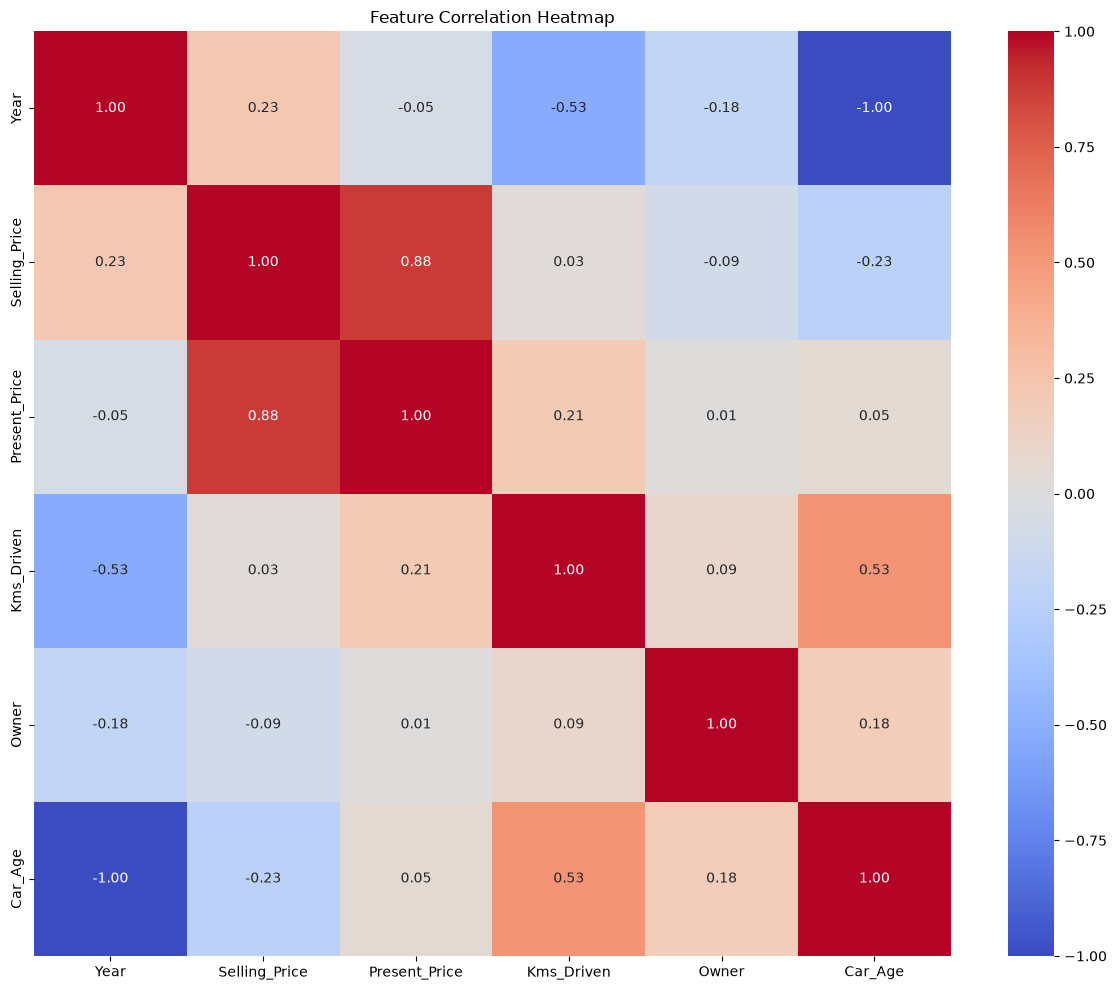

In [9]:
numeric_cols = df_encoded.select_dtypes(include=[np.number]).columns
corr_matrix = df_encoded[numeric_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', vmin=-1, vmax=1)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

## Train/test split

In [10]:
from sklearn.model_selection import train_test_split

feature_cols = [c for c in df_encoded.columns if c not in ['Car_Name', 'Brand', 'Selling_Price', 'Year']]
X = df_encoded[feature_cols]
y = df_encoded['Selling_Price']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

## Training  regression models

In [11]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)

## Evaluate with MAE, RMSE, R²

In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

for name, model in models.items():
    y_pred = model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    r2 = r2_score(y_test, y_pred)
    print(f"--- {name} ---")
    print(f"MAE: {mae:.3f}")
    print(f"RMSE: {rmse:.3f}")
    print(f"R²: {r2:.3f}\n")

--- Linear Regression ---
MAE: 1.473
RMSE: 2.524
R²: 0.753

--- Random Forest ---
MAE: 1.408
RMSE: 3.322
R²: 0.572



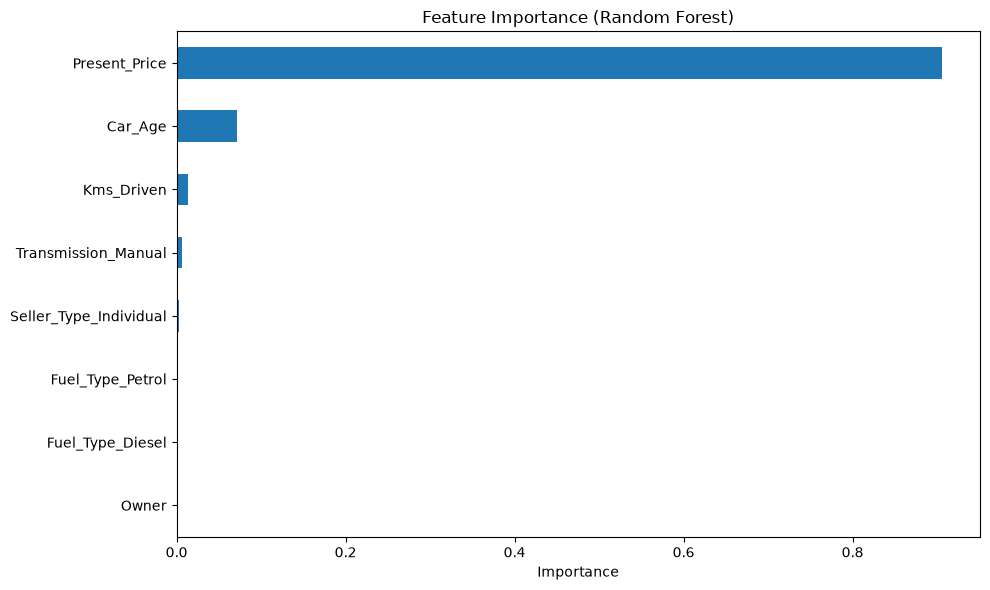

In [13]:
best_model = models['Random Forest']  # adjust based on your actual best R² result

importances = pd.Series(best_model.feature_importances_, index=feature_cols).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
importances.head(10).plot(kind='barh')
plt.xlabel('Importance')
plt.title('Feature Importance (Random Forest)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()